# Exercise 1: Noise and estimation precision

We revisit the lecture's simple linear model:
$$
y_i = \alpha + \beta x_i + \epsilon_i,
\qquad \alpha = 1,\quad \beta = 0.5,
\qquad \epsilon_i \stackrel{\text{iid}}{\sim} N(0, \sigma^2).
$$
The explanatory variable $x_i$ is uniformly distributed on $[0, 10]$ and
independent of the noise $\epsilon_i$. How do the noise standard deviation $\sigma$ and
sample size $N$ affect the estimated intercept and slope?

The sample-generation function below is taken from the lecture. A plotting helper is
also provided which you can use to visualize the sample, the true relationship, and the estimated regression line. 
Run their cells before starting the exercise.

In [1]:
def create_sample(N, alpha, beta, sigma):
    """
    Create sample for simple linear regression

    Parameters
    ----------
    N : int
        Sample size
    alpha : float
        Intercept (or bias)
    beta : float
        Slope (or weight)
    sigma : float
        Standard deviation of the error term

    Returns
    -------
    x : array
        Predictor variable, uniformly distributed on [0, 10]
    y : array
        Outcome variable
    """
    from numpy.random import default_rng

    # Initialize random number generator with a fixed seed
    rng = default_rng(seed=1234)

    # Use x that are uniformly distributed on [0, 10]
    x = rng.uniform(0, 10, size=N)

    # Normally distributed errors
    epsilon = rng.normal(scale=sigma, size=N)

    # Create outcome variable
    y = alpha + beta * x + epsilon

    return x, y

The plotting helper takes the sample arrays `x` and `y`, a fitted model, the
true intercept `alpha` and slope `beta`, and a title. It plots the sample with
the true and estimated lines.

In [2]:
import matplotlib.pyplot as plt
import numpy as np


def plot_sample(x, y, model, alpha, beta, title, ylim=None):
    """
    Plot a regression sample with the true and estimated lines.

    Parameters
    ----------
    x : array
        Explanatory variable
    y : array
        Outcome variable
    model : object
        Fitted linear regression model
    alpha : float
        True intercept
    beta : float
        True slope
    title : str
        Plot title
    ylim : tuple, optional
        y-axis limits (ymin, ymax)
    """
    _fig, ax = plt.subplots(figsize=(5, 3.5), layout='constrained')
    x_grid = np.linspace(0, 10, 101)
    y_true = alpha + beta * x_grid
    X_grid = x_grid[:, None]
    y_hat = model.predict(X_grid)

    ax.scatter(x, y, s=15, c='steelblue', alpha=0.5, label='Sample')
    ax.plot(x_grid, y_true, c='black', lw=1.5, ls='--', label='True line')
    ax.plot(x_grid, y_hat, c='darkorange', lw=1.5, label='Estimated line')

    # Add text with alpha and beta estimates in the lower right corner of the plot
    ax.text(
        0.95,
        0.05,
        rf'$\widehat{{\alpha}} = {model.intercept_:.3f}, \widehat{{\beta}} = {model.coef_[0]:.3f}$',
        transform=ax.transAxes,
        ha='right',
        va='bottom',
    )
    # Add remaining annotations
    ax.set_title(title)
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
    ax.set_xlim(0, 10)
    if ylim is not None:
        ax.set_ylim(ylim)
    ax.legend()

***
## Part 1 — Increasing the noise

First, you are going to investigate how the estimated model coefficients change as the noise standard deviation $\sigma$ increases.

Fix $N=50$, $\alpha=1$, and $\beta=0.5$. Write a loop over
$\sigma \in \{0.2, 0.7, 2.0\}$. For each noise standard deviation:

1. Generate a sample using `create_sample()`. The fixed seed keeps the $x$
   values and underlying standard-normal noise draws identical across noise
   levels; only the noise scale changes.
2. Fit a
   [`LinearRegression()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
   model, using `X = x[:, None]` as the feature matrix.
3. Print `model.intercept_` and `model.coef_[0]`, and compare them with the
   true values.
4. Call `plot_sample()` to visualize the sample, the true line, and the estimated line.

How does increasing $\sigma$ affect the scatter around the true line and the
coefficient estimates?

### Solution

sigma = 0.2: intercept = 1.107, slope = 0.495
sigma = 0.7: intercept = 1.376, slope = 0.482
sigma = 2.0: intercept = 2.075, slope = 0.449


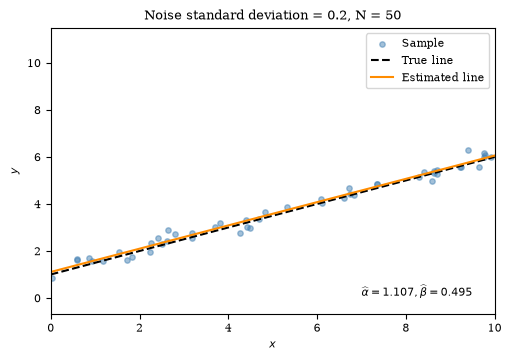

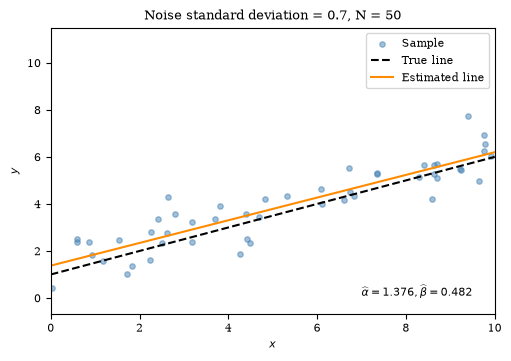

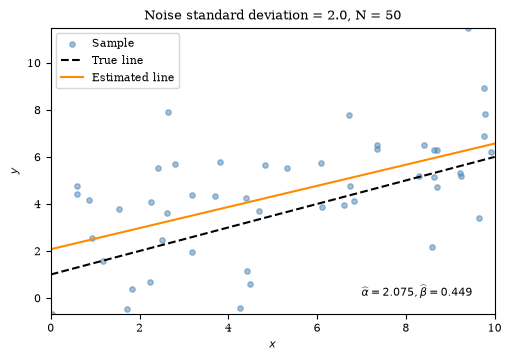

In [3]:
from sklearn.linear_model import LinearRegression

# Sample size and parameters
N = 50
alpha = 1.0
beta = 0.5
sigmas = [0.2, 0.7, 2.0]

# Create samples for all sigmas
samples = [create_sample(N, alpha, beta, sigma) for sigma in sigmas]

# Compute harmonized y-axis limits for all plots
y_min = min(y.min() for _, y in samples)
y_max = max(y.max() for _, y in samples)

# Loop over different noise levels
for sigma, (x, y) in zip(sigmas, samples, strict=True):

    # Fit linear regression model
    model = LinearRegression()
    model.fit(x[:, None], y)

    print(
        f'sigma = {sigma:.1f}: intercept = {model.intercept_:.3f}, '
        f'slope = {model.coef_[0]:.3f}'
    )

    title = f'Noise standard deviation = {sigma:.1f}, N = {N}'
    plot_sample(x, y, model, alpha, beta, title, ylim=(y_min, y_max))

The observations spread farther from the true line as $\sigma$ increases.
With the same $x$ values and standard-normal noise draws, the deviations of the
estimated intercept and slope from their true values scale with $\sigma$.

Larger noise increases the variability of OLS estimates across repeated samples.
It does not introduce bias: because the errors have mean zero conditional on $x$,
the estimates equal the true coefficients on average over repeated samples.

<span style="display: none;">SolutionEnd</span>

***
## Part 2 — Increasing the sample size

Fix $\sigma=2.0$ and compare samples of $N=50$ and $N=1{,}000$, keeping
$\alpha=1$ and $\beta=0.5$. For each sample size:

1. Draw a sample using `create_sample()`. 
2. Fit each model and print its estimated intercept and slope.
3. Call `plot_sample()` to visualize the sample, the true line, and the estimated line.
 
Are the estimates closer to the true values in the larger sample?
Explain why a larger sample improves coefficient precision without reducing the underlying noise.

### Solution

N =   50: intercept = 2.075, slope = 0.449
N = 1000: intercept = 1.045, slope = 0.485


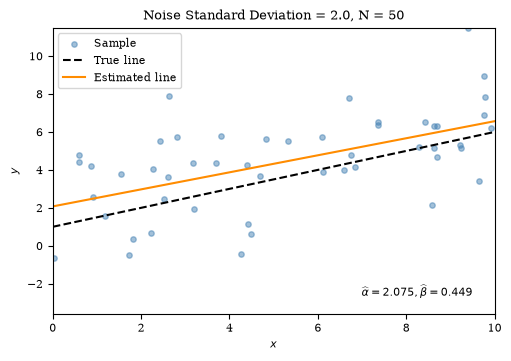

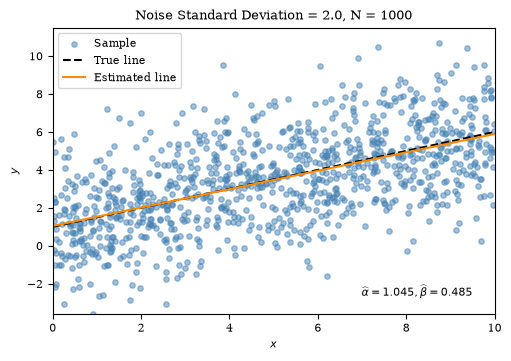

In [4]:
sigma = 2.0
sample_sizes = [50, 1000]

# Create a sample for each sample size
samples = [create_sample(N, alpha, beta, sigma) for N in sample_sizes]

# Compute harmonized y-axis limits for all plots
y_min = min(y.min() for _, y in samples)
y_max = max(y.max() for _, y in samples)

for N, (x, y) in zip(sample_sizes, samples, strict=True):
    model = LinearRegression()
    model.fit(x[:, None], y)

    print(
        f'N = {N:4d}: intercept = {model.intercept_:.3f}, slope = {model.coef_[0]:.3f}'
    )
    title = f'Noise Standard Deviation = {sigma:.1f}, N = {N}'
    plot_sample(x, y, model, alpha, beta, title, ylim=(y_min, y_max))

In this comparison, increasing $N$ from $50$ to $1{,}000$ moves the estimated
intercept from $2.075$ to $1.045$ and the estimated slope from $0.449$ to $0.485$.
Both estimates are closer to their true values, $\alpha=1$ and $\beta=0.5$.

With more observations, individual random errors have less influence on the fitted
line, and positive and negative errors tend to cancel more effectively. This
generally improves coefficient precision, although a larger sample does not
guarantee closer estimates for every draw.

The noise standard deviation remains $\sigma=2.0$. The larger sample produces a
denser cloud of points, but the underlying spread around the true line stays the
same.

<span style="display: none;">SolutionEnd</span>

***
# Exercise 2: Polynomial under- and overfitting

Consider the following non-linear model,
$$
\begin{aligned}
y_i &= f(x_i) + \epsilon_i \\
f(x) &= \cos\left(\frac{3}{2} \pi x \right) \\
\epsilon_i &\stackrel{\text{iid}}{\sim} N(0, \sigma_{\epsilon}^2)
\end{aligned}
$$
where $y_i$ is a trigonometric function of $x_i$ but is measured with an additive error $\epsilon_i$. In this exercise, we are going to approximate $y_i$ using polynomials in $x_i$ of varying degrees.

***
## Part 1 — Creating and plotting a sample

The function `fcn()` implements the true relationship $y=f(x)$.

In [5]:
import numpy as np


def fcn(x):
    """
    True function without errors.
    """
    return np.cos(1.5 * np.pi * x)

Using `fcn()`, create a sample of size $N=50$. Draw the $x_i$ from a uniform
distribution on $[-1, 1]$ and use $\sigma_{\epsilon}=0.2$. Initialize your RNG
with seed 123, then generate $y_i$ according to the model above.

Create a scatter plot of the sample $(x_i, y_i)$ and add a line showing the true
relationship without measurement error.

### Solution

We first draw a sample of $x$ and $\epsilon$ and compute the values of $y$ using the
true relationship implemented in `fcn()`:

In [6]:
from numpy.random import default_rng

# Initialize random number generator
rng = default_rng(seed=123)

# Sample size
N = 50
# Standard deviation of error term
sigma = 0.2

# Draw explanatory variable x from uniform distribution
x = rng.uniform(-1, 1, size=N)

# Draw error term from normal distribution
epsilon = rng.normal(scale=sigma, size=N)
y = fcn(x) + epsilon

The following code plots the sample and the true function $y = f(x)$:

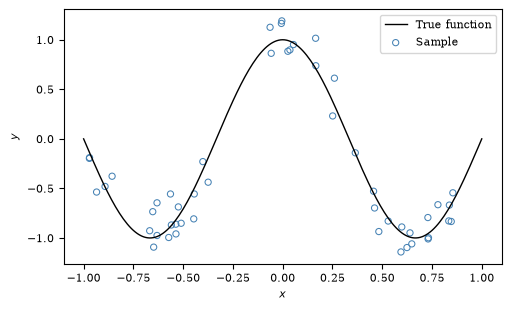

In [7]:
import matplotlib.pyplot as plt

xvalues = np.linspace(-1.0, 1.0, 201)
y_true = fcn(xvalues)

fig, ax = plt.subplots(figsize=(5, 3), layout='constrained')

# Plot true function and sample
ax.plot(xvalues, y_true, c='black', lw=1.0, label='True function')
ax.scatter(x, y, s=20, c='none', ec='steelblue', lw=0.75, label='Sample')

ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.legend()

<span style="display: none;">SolutionEnd</span>

***
## Part 2 — Polynomial approximations

First, convert the sample's explanatory variable to a feature matrix using
`X = x[:, None]`.

Complete the template for `plot_poly_degrees()` below to create a figure with
6 subplots, showing fitted polynomials of degrees
$d \in \{0, 1, 2, 4, 6, 12\}$. Each panel should also show the sample scatter
plot and the true function $y=f(x)$.

How does the approximation change as you increase $d$? Do higher-degree
polynomials always predict new observations better?

*Hints:*

- Build a pipeline, for example using
  [`make_pipeline()`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html)
  to combine the
  [`PolynomialFeatures()`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)
  transformation and
  [`LinearRegression()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
  to approximate $y$ as a polynomial in $x$.

- When creating polynomials with
  `PolynomialFeatures(..., include_bias=True)`,
  use `LinearRegression(fit_intercept=False)`. The polynomial transformation
  already includes the constant term.

In [8]:
import matplotlib.pyplot as plt


def plot_poly_degrees(degrees, X, y):
    """
    Fit and plot polynomial regression models of different degrees.

    Parameters
    ----------
    degrees : array-like
        List of polynomial degrees to fit and plot.
    X : array-like
        Explanatory variable.
    y : array-like
        Response variable.
    """

    # Create figure with 3 columns
    ncol = 3
    nrow = int(np.ceil(len(degrees) / ncol))

    _fig, axes = plt.subplots(
        nrow, ncol, figsize=(8, 5), sharex=True, sharey=True, layout='constrained'
    )

    # x-values for predicting & plotting
    xvalues = np.linspace(-1.0, 1.0, 201)
    # True y-values
    y_true = fcn(xvalues)

    for i, ax in enumerate(axes.flatten()):
        # Degree for current sub-plot
        d = degrees[i]

        # TODO: Create polynomial transformation + estimation pipeline

        # TODO: Fit the model to the sample data

        # TODO: Predict the response variable for the x-values

        # TODO: Plot predicted values

        # Plot true relationship
        ax.plot(xvalues, y_true, c='black', lw=1.0)
        # Plot sample as scatter plot
        ax.scatter(X, y, s=20, c='none', ec='steelblue', lw=0.75)
        ax.set_ylim((-1.5, 1.5))
        ax.legend()

### Solution

The code below shows the complete function.

In [9]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures


def plot_poly_degrees(degrees, X, y):
    """
    Fit and plot polynomial regression models of different degrees.

    Parameters
    ----------
    degrees : array-like
        List of polynomial degrees to fit and plot.
    X : array-like
        Explanatory variable.
    y : array-like
        Response variable.
    """

    # Create figure with 3 columns
    ncol = 3
    nrow = int(np.ceil(len(degrees) / ncol))

    _fig, axes = plt.subplots(
        nrow, ncol, figsize=(8, 5), sharex=True, sharey=True, layout='constrained'
    )

    # x-values for predicting & plotting
    xvalues = np.linspace(-1.0, 1.0, 201)
    # True y-values
    y_true = fcn(xvalues)

    for i, ax in enumerate(axes.flatten()):
        # Degree for current sub-plot
        d = degrees[i]

        # Create Pipeline object that consists of a polynomial transformation and
        # a linear regression model
        pipe_lr = make_pipeline(
            PolynomialFeatures(degree=d, include_bias=True),
            LinearRegression(fit_intercept=False),
        )

        # Fit model using current polynomial degree
        pipe_lr.fit(X, y)

        # Compute predicted values
        y_hat = pipe_lr.predict(xvalues[:, None])

        # Plot predicted values
        ax.plot(xvalues, y_hat, lw=1.25, c='darkorange', label=f'Degree {d}')

        # Plot true relationship and sample
        ax.plot(xvalues, y_true, c='black', lw=1.0)
        ax.scatter(X, y, s=20, c='none', ec='steelblue', lw=0.75)
        ax.set_ylim((-1.5, 1.5))
        ax.legend()

With this implementation, we define the list of polynomial degrees to plot and call the function we just implemented.

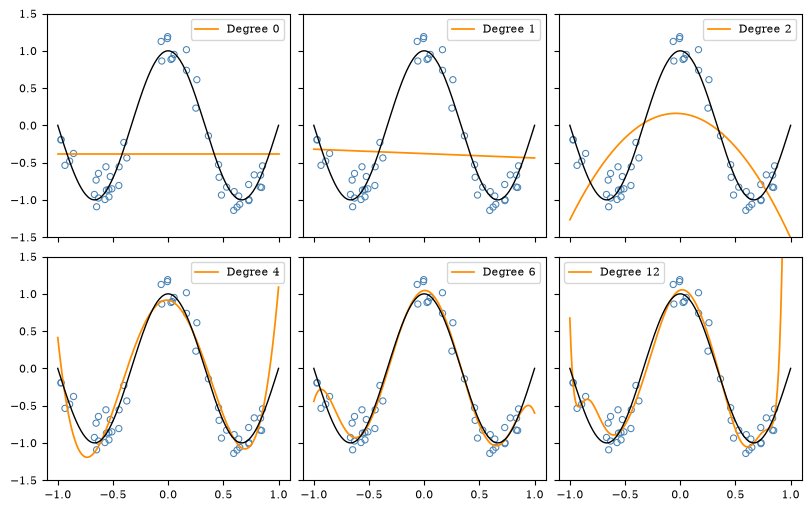

In [10]:
# Polynomial degrees to plot
degrees = np.array([0, 1, 2, 4, 6, 12])

# Convert features to a matrix for scikit-learn
X = x[:, None]

# Fit and plot polynomial regression models of different degrees
plot_poly_degrees(degrees, X, y)

A degree-0 polynomial is a constant, and a degree-1 polynomial is a straight line.
Both miss the curved relationship and underfit. The degree-2 polynomial captures
some curvature but cannot reproduce the central peak and both troughs, so it also
underfits. Degrees 4 and 6 approximate the true function much better. The degree-12
fit has extra bends that follow sample noise, especially near the ends of the
interval.

A closer fit to the sample does not necessarily improve predictions for new
observations. We evaluate this next using a split into training and validation
sets.

<span style="display: none;">SolutionEnd</span>

***
## Part 3 — Training and validation errors

Evaluate how well polynomials of degrees $d=0, 1, \dots, 12$ fit the training
data and predict unseen observations.

Use
[`train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
from `sklearn.model_selection` to split `(X, y)` into training (70%) and
validation (30%) subsets, setting `random_state=123`.

The validation set helps choose the polynomial degree. A separate test set is
reserved for evaluating prediction error after that choice is fixed. We do not
use a test set in this exercise.

Next, complete the template for `compute_poly_mse()` below. The function takes a
single polynomial degree `d` and the training and validation data. It should:

1. Build a pipeline combining `PolynomialFeatures(degree=d, include_bias=True)`
   and `LinearRegression(fit_intercept=False)`.
2. Fit the pipeline on the training data `(X_train, y_train)`.
3. Predict the response on both the training and validation sets.
4. Compute the mean squared error (MSE) on each subset using
   [`mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html).

Return the two MSEs as `mse_train, mse_val`.

In [11]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# TODO: Split sample into training (70%) and validation (30%) sets
# X_train, X_val, y_train, y_val = ...


def compute_poly_mse(d, X_train, y_train, X_val, y_val):
    """
    Compute training and validation MSEs for one polynomial degree.

    Parameters
    ----------
    d : int
        Polynomial degree
    X_train : array
        Training feature matrix
    y_train : array
        Training outcomes
    X_val : array
        Validation feature matrix
    y_val : array
        Validation outcomes

    Returns
    -------
    mse_train : float
        Training MSE
    mse_val : float
        Validation MSE
    """
    # TODO: Build pipeline
    # TODO: Fit on training data
    # TODO: Predict on training and validation data
    # TODO: Compute and return the two MSEs

### Solution

We split the sample and implement `compute_poly_mse()` for a single degree:

In [12]:
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# Split sample into training (70%) and validation (30%) sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=123)


def compute_poly_mse(d, X_train, y_train, X_val, y_val):
    """
    Compute training and validation MSEs for one polynomial degree.

    Parameters
    ----------
    d : int
        Polynomial degree
    X_train : array
        Training feature matrix
    y_train : array
        Training outcomes
    X_val : array
        Validation feature matrix
    y_val : array
        Validation outcomes

    Returns
    -------
    mse_train : float
        Training MSE
    mse_val : float
        Validation MSE
    """
    # Build a pipeline containing a polynomial transformation and a linear
    # regression model
    pipe = make_pipeline(
        PolynomialFeatures(degree=d, include_bias=True),
        LinearRegression(fit_intercept=False),
    )
    # Fit the model to the training data
    pipe.fit(X_train, y_train)

    # Predict the response variable for the training and validation data
    y_train_hat = pipe.predict(X_train)
    y_val_hat = pipe.predict(X_val)

    # Compute MSEs for training and validation data
    mse_train = mean_squared_error(y_train, y_train_hat)
    mse_val = mean_squared_error(y_val, y_val_hat)

    return mse_train, mse_val

<span style="display: none;">SolutionEnd</span>

***
## Part 4 — Optimal polynomial degree and error curves

Iterate over polynomial degrees $d=0, 1, \dots, 12$. For each degree, call
`compute_poly_mse()` and save the training and validation MSEs.

Plot the training MSE and validation MSE against $d$. Use
[`np.argmin()`](https://numpy.org/doc/stable/reference/generated/numpy.argmin.html)
to determine which degree gives the lowest validation MSE.

How do the training and validation errors change as the degree increases? Explain why
the model with the lowest training MSE may predict new observations poorly.

### Solution

We compute the errors over all 13 candidate degrees and plot the results:

In [13]:
# Sequence of candidate polynomial degrees
degrees = np.arange(13)

# Collect training and validation MSEs for each degree
mse_train = []
mse_val = []
for d in degrees:
    train_error, val_error = compute_poly_mse(d, X_train, y_train, X_val, y_val)
    mse_train.append(train_error)
    mse_val.append(val_error)

# Find degree that minimizes validation MSE
d_opt = degrees[np.argmin(mse_val)]

print(f'Polynomial degree with lowest validation MSE: {d_opt}')
print(f'Validation MSE at optimal degree: {mse_val[d_opt]:.4f}')

Polynomial degree with lowest validation MSE: 6
Validation MSE at optimal degree: 0.0192


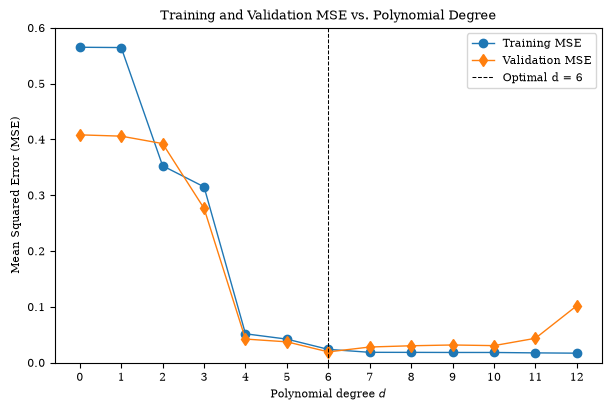

In [14]:
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')

ax.plot(degrees, mse_train, label='Training MSE', marker='o', lw=1.0)
ax.plot(degrees, mse_val, label='Validation MSE', marker='d', lw=1.0)
ax.axvline(d_opt, c='black', ls='--', lw=0.75, label=f'Optimal d = {d_opt}')

ax.set_xlabel('Polynomial degree $d$')
ax.set_ylabel('Mean Squared Error (MSE)')
ax.set_xticks(degrees)
ax.set_ylim(0.0, 0.6)
ax.legend()
_ = ax.set_title('Training and Validation MSE vs. Polynomial Degree')

Training MSE decreases at every degree in this sample. Each higher-degree
polynomial includes all the terms of the lower-degree model, so it can fit the
training data at least as well.

Validation MSE falls to its minimum of about 0.0192 at $d=6$. It then rises overall,
reaching about 0.1020 at $d=12$, while training MSE continues to fall. The extra
flexibility fits noise in the training sample and makes predictions for unseen
observations worse.

The validation curve has small fluctuations; it need not increase at every step.
The best degree also depends on the sample and split.

<span style="display: none;">SolutionEnd</span>

***
## Part 5 — Plotting the fitted model

Re-estimate the model on the training set using the degree selected in Part 4.
Create a plot showing:

- The true relationship $y=f(x)$
- The training observations
- The validation observations, using a distinct marker and color
- The fitted polynomial curve evaluated on a dense grid $x \in [-1, 1]$

### Solution

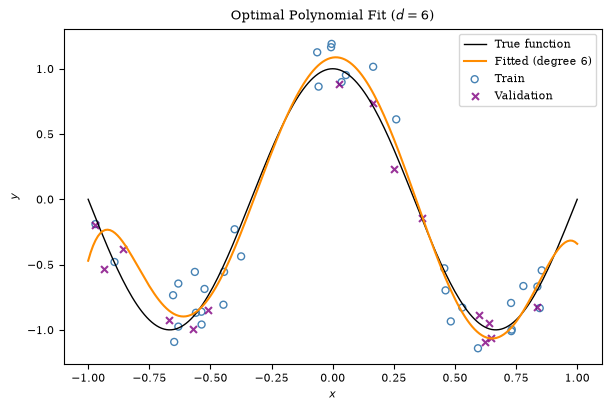

In [15]:
# Refit pipeline using optimal degree on training data
pipe_opt = make_pipeline(
    PolynomialFeatures(degree=d_opt, include_bias=True),
    LinearRegression(fit_intercept=False),
)
pipe_opt.fit(X_train, y_train)

# Dense grid for plotting smooth curve. Convert to matrix for scikit-learn
x_grid = np.linspace(-1.0, 1.0, 201)[:, None]
y_pred = pipe_opt.predict(x_grid)

# Plot true function, fitted polynomial, and both samples
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')

ax.plot(x_grid, fcn(x_grid), c='black', lw=1.0, label='True function')
ax.plot(x_grid, y_pred, c='darkorange', lw=1.5, label=f'Fitted (degree {d_opt})')

# Plot training sample
ax.scatter(X_train, y_train, s=25, fc='none', ec='steelblue', label='Train')
# Plot validation sample
ax.scatter(X_val, y_val, s=25, c='purple', marker='x', alpha=0.8, label='Validation')

ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.legend()
_ = ax.set_title(f'Optimal Polynomial Fit ($d={d_opt}$)')

<span style="display: none;">SolutionEnd</span>